# Iniciação Científica
Aluno: Enzo Januzzi Xavier

Orientador: James Morais de Almeida

# Energia livre de Gibbs dos intermediários

## Importações e definições

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import warnings

In [14]:
warnings.filterwarnings("ignore")

# ==============================================================================
# 1. CONFIGURATION & FILE PATHS
# ==============================================================================

# Automatically detect the Excel file name (with or without underscore)
XLSX = "Data/IC_-_Enzo.xlsx" if os.path.exists("Data/IC_-_Enzo.xlsx") else "Data/IC - Enzo.xlsx"

SHOW_FINAL = True           # True -> appends "* + NH3(g) + H2O" to close the cycle
SHIFT_START_TO_ZERO = True  # True -> sets the first intermediate (*NO / *ON) to 0.00 eV
U_EQ = 0.71                 # Equilibrium potential (V vs. RHE) for NO + 5(H+ + e-) -> NH3 + H2O

OUTPUT_DIR = "figuras_relatorio"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [27]:
# ==============================================================================
# 2. DFT ENERGIES & THERMAL CORRECTIONS (ZPE - TS in eV at 298.15 K)
# ==============================================================================

# Electronic energies (eV) from VASP (clean NP and isolated gas molecules)
E = {
    "NP":  -350.413981,
    "NO":   -12.298138,
    "H2":    -6.731708,
    "H2O":  -14.217770,
    "NH3":  -19.537933,
}

# Gas-phase (ZPE - TS) corrections (eV, 298.15 K; H2O at 0.035 bar liquid-vapor eq.)
ZTS_GAS = {
    "NO":  0.12 - 0.65,
    "H2":  0.27 - 0.40,
    "H2O": 0.56 - 0.67,
    "NH3": 0.89 - 0.60,
}

# Adsorbate (ZPE - TS) corrections (eV, from the 'Gibbs' sheet)
ZTS_ADS = {
    "NO":   0.17 - 0.17,
    "NOH":  0.44 - 0.19,
    "N":    0.04 - 0.10,
    "NH":   0.29 - 0.09,
    "NH2":  0.65 - 0.58,
    "ON":   0.17 - 0.16,
    "ONH":  0.440104 - 0.205463,
    "ONH2": 0.777231 - 0.151637,
    "O":    0.070805 - 0.045773,
    "OH":   0.336039 - 0.119717,
}

# Stoichiometric coefficients (a, b, c, n) relative to NO(g) + 5/2 H2(g):
# E_ref(s) = E(NO) + a*E(H2) + b*E(H2O) + c*E(NH3)
# n = number of (H+ + e-) pairs transferred starting from adsorbed *NO / *ON
REF = {
    # N-down pathway
    "NO":    (0.0,  0.0,  0.0, 0),
    "NOH":   (0.5,  0.0,  0.0, 1),
    "N":     (1.0, -1.0,  0.0, 2),
    "NH":    (1.5, -1.0,  0.0, 3),
    "NH2":   (2.0, -1.0,  0.0, 4),
    # O-down pathway
    "ON":    (0.0,  0.0,  0.0, 0),
    "ONH":   (0.5,  0.0,  0.0, 1),
    "ONH2":  (1.0,  0.0,  0.0, 2),
    "O":     (1.5,  0.0, -1.0, 3),
    "OH":    (2.0,  0.0, -1.0, 4),
    # Desorbed final state: * + NH3(g) + H2O
    "final": (2.5, -1.0, -1.0, 5),
}

PATHS = {
    "N-down (*NOH)": ["NO", "NOH", "N", "NH", "NH2"],
    "O-down (*ONH)": ["ON", "ONH", "ONH2", "O", "OH"],
}

SITES = {
    0: "atop (14)",
    1: "bridge (14,16)",
    2: "hollow (14,16,26)",
    3: "hollow HCP (14,16,41)",
    4: "atop (34)",
}

SLUG_SITES = {
    0: "atop_14",
    1: "bridge_14_16",
    2: "hollow_14_16_26",
    3: "hollow_HCP_14_16_41",
    4: "atop_34",
}

# Formatted x-axis labels with line breaks (\n) to prevent tick overlap
LABEL = {
    "NO":    "*NO",
    "NOH":   "*NOH",
    "N":     "*N",
    "NH":    "*NH",
    "NH2":   "*NH$_2$",
    "ON":    "*ON",
    "ONH":   "*ONH",
    "ONH2":  "*ONH$_2$",
    "O":     "*O",
    "OH":    "*OH",
    "final": "* + NH$_3$(g)\n+ H$_2$O(l)",
}

In [26]:
# ==============================================================================
# 3. FUNCTIONS
# ==============================================================================

def ref_E(state):
    """Returns the stoichiometric gas-phase electronic reference energy (eV)."""
    a, b, c, _ = REF[state]
    return E["NO"] + a * E["H2"] + b * E["H2O"] + c * E["NH3"]

def ref_ZTS(state):
    """Returns the stoichiometric gas-phase (ZPE - TS) reference correction (eV)."""
    a, b, c, _ = REF[state]
    return (
        ZTS_GAS["NO"]
        + a * ZTS_GAS["H2"]
        + b * ZTS_GAS["H2O"]
        + c * ZTS_GAS["NH3"]
    )

def E_sist(state, conf):
    """Fetches the converged total DFT energy (Esist) from the 'Geral' sheet."""
    row = geral[(geral.Intermed == state) & (geral.Conf == conf)]
    val = pd.to_numeric(row.Esist, errors="coerce")
    return float(val.iloc[0]) if len(val) and np.isfinite(val.iloc[0]) else np.nan

def G0_cumulative(state, conf):
    """
    Calculates cumulative Gibbs free energy ΔG(U = 0 V) relative to
    NO(g) + 5/2 H2(g) + clean NP.
    """
    if state == "final":
        e_sys, zts = E["NP"], 0.0
    else:
        e_sys, zts = E_sist(state, conf), ZTS_ADS[state]

    if not np.isfinite(e_sys):
        return np.nan

    dE = e_sys - E["NP"] - ref_E(state)
    dZTS = zts - ref_ZTS(state)
    return dE + dZTS

def analyse(path, conf):
    """
    Computes the Gibbs free energy profile, translates the initial state (*NO/*ON)
    to 0.00 eV if SHIFT_START_TO_ZERO is enabled, and identifies the PDS, U_L, and η.
    """
    states = path + (["final"] if SHOW_FINAL else [])
    g_raw = np.array([G0_cumulative(s, conf) for s in states])
    n = np.array([REF[s][3] for s in states])

    # If any intermediate failed to converge, return NaNs
    if np.any(~np.isfinite(g_raw)):
        return states, g_raw, n, np.nan, None, np.nan

    # Save the unshifted adsorption free energy of *NO / *ON for reference in tables
    g_ads_init = float(g_raw[0])

    # Translate all intermediates so that *NO (or *ON) starts at 0.00 eV
    g = (g_raw - g_raw[0]) if SHIFT_START_TO_ZERO else g_raw.copy()

    # Step free energies ΔG_k between consecutive electrochemical steps (Δn = 1)
    steps = np.diff(g)
    ipds = int(np.argmax(steps))
    UL = -steps[ipds]  # Limiting potential for reduction: U_L = -max(ΔG_k) / e

    return states, g, n, UL, ipds, g_ads_init

def plot_fed(ax, states, g, n, UL, ipds, title):
    """Plots the Free Energy Diagram (CHE Model) for NORR on Cu@Ru Nanoparticles.
    Data source: IC_-_Enzo.xlsx (Sheet: 'Geral')

    Thermodynamic Convention:
    1. Unshifted cumulative free energy (relative to NO(g) + 5/2 H2(g) + clean NP):
        ΔG_i(0) = [E_sys(i) - E_NP - E_ref(i)] + [ZTS_ads(i) - ZTS_ref(i)]
    2. Shifted free energy (anchoring the initial adsorbed state *NO or *ON at 0.00 eV):
        ΔG_i_shifted(0) = ΔG_i(0) - ΔG_0(0)
    3. Potential dependence (for reduction, n = number of H+ + e- transferred from *NO/*ON):
        ΔG_i(U) = ΔG_i_shifted(0) + n_i * e * U   (where U is potential vs. RHE)

    Note on Product (*NH3):
    Adsorbed *NH3 did not converge on the hollow sites. The thermodynamic cycle is
    closed using the desorbed state (* + NH3(g) + H2O), which requires only the
    clean nanoparticle energy (E_NP) and gas-phase references.
    """
    
    x = np.arange(len(states))
    half_width = 0.32

    curves = [
        (0.0,  "#3b6fd8", "U = 0 V"),
        (U_EQ, "#999999", f"U = {U_EQ} V (eq.)"),
        (UL,   "#d8573b", f"U = U$_L$ = {UL:.2f} V"),
    ]

    for U, col, lab in curves:
        if not np.isfinite(U):
            continue
        y = g + n * U

        # Plot horizontal energy steps
        for xi, yi in zip(x, y):
            ax.hlines(yi, xi - half_width, xi + half_width, color=col, lw=3, zorder=3)

        # Plot dashed connectors between steps
        ax.plot(
            np.repeat(x, 2)[1:-1] + np.tile([half_width, -half_width], len(x) - 1),
            np.repeat(y, 2)[1:-1],
            ls="--",
            color=col,
            lw=1.1,
            alpha=0.7,
            zorder=2,
        )
        ax.plot([], [], color=col, lw=3, label=lab)

        # Annotate numerical values for the U = 0 V curve
        if U == 0.0:
            for xi, yi in zip(x, y):
                ax.text(
                    xi,
                    yi + 0.08,
                    f"{yi:.2f}",
                    ha="center",
                    va="bottom",
                    fontsize=10,
                    fontweight="bold",
                    color=col,
                    zorder=4,
                )

    # Highlight the Potential-Determining Step (PDS) on top of dashed lines
    if ipds is not None:
        ax.annotate(
            "PDS",
            xy=(ipds + 0.5, (g[ipds] + g[ipds + 1]) / 2),
            ha="center",
            va="center",
            fontsize=10,
            color="#d8573b",
            weight="bold",
            zorder=5,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
        )

    ax.set_xticks(x)
    ax.set_xticklabels([LABEL[s] for s in states], fontsize=12)
    ax.axhline(0, color="k", lw=0.6, ls=":", zorder=1)
    ax.legend(fontsize=10, loc="lower left", frameon=True, facecolor="white", framealpha=0.8)
    ax.spines[["top", "right"]].set_visible(False)

    ax.set_xlabel("Coordenada de Reação", fontweight="bold", fontsize=12)
    ax.set_ylabel("Energia livre ($\Delta$G, eV)", fontweight="bold", fontsize=12)
    ax.set_title(title, fontsize=14, pad=12)

    # Expand y-limits slightly to prevent text labels from clipping at the top
    y_all = np.concatenate([g, g + n * U_EQ, g + n * UL])
    y_min, y_max = np.nanmin(y_all), np.nanmax(y_all)
    ax.set_ylim(y_min - 0.5, y_max + 0.7)

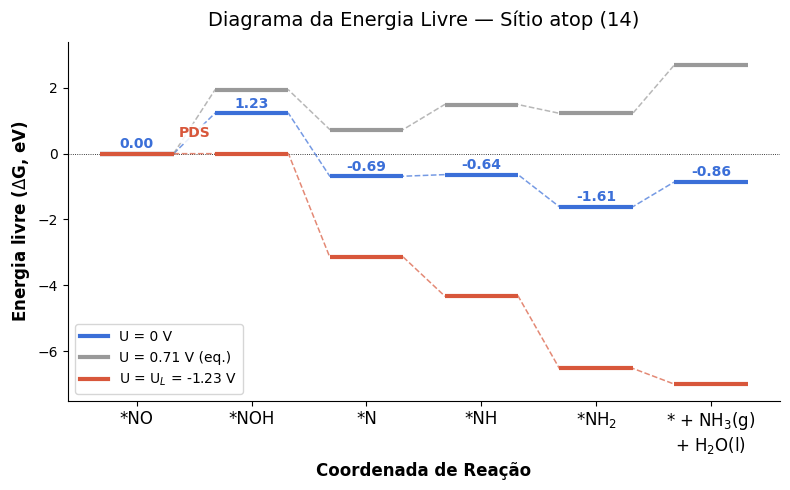

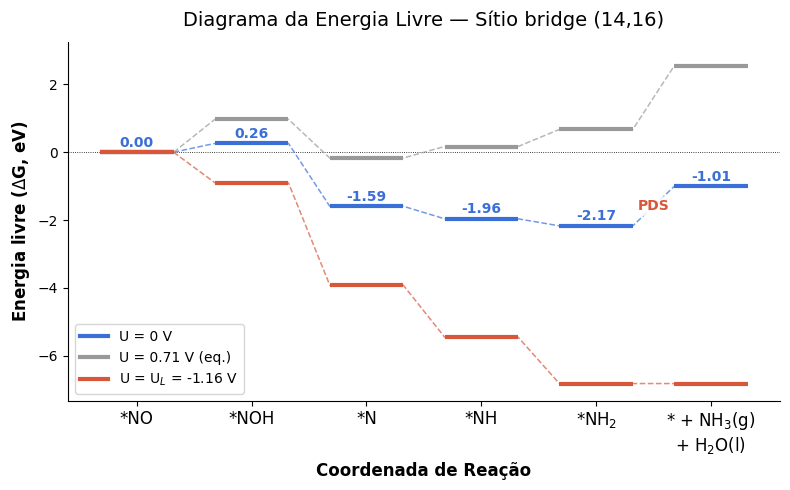

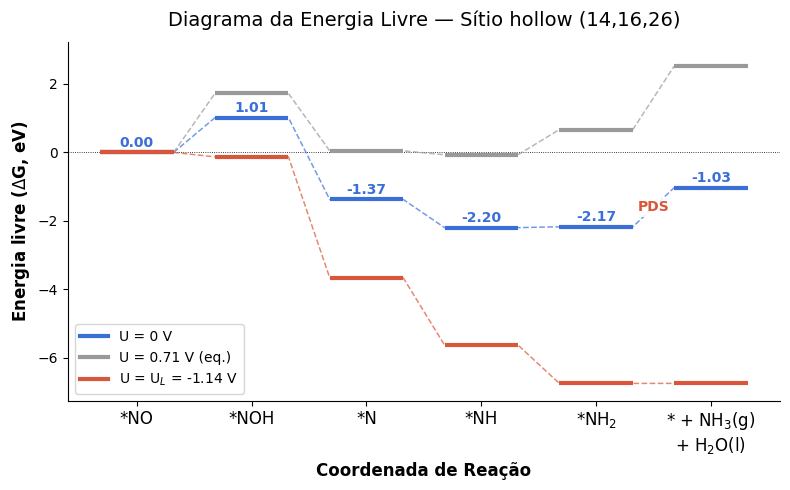

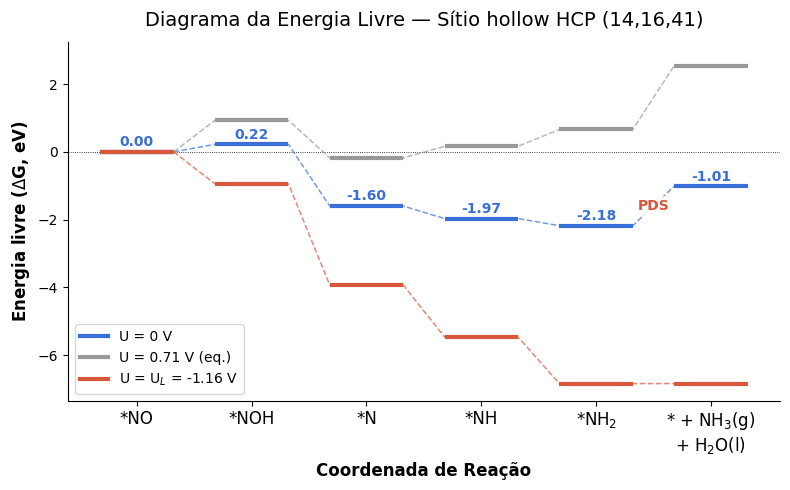

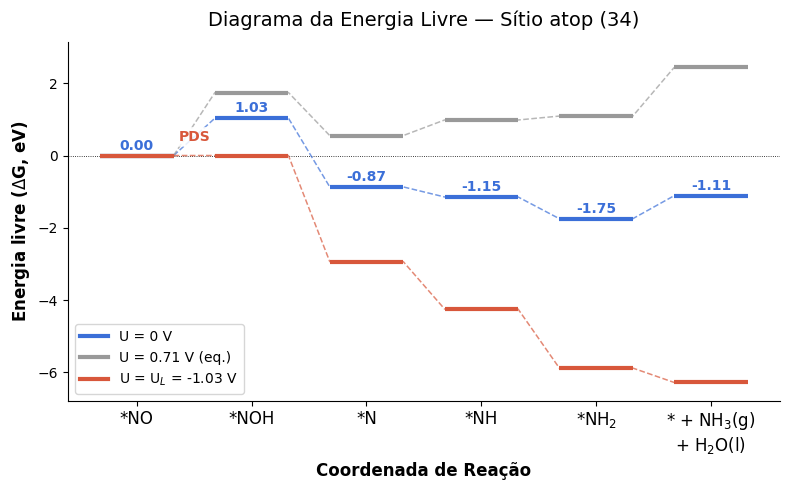

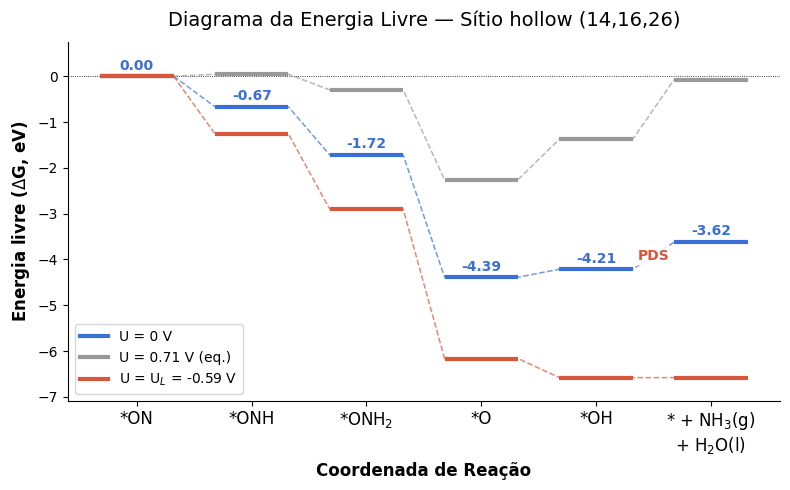

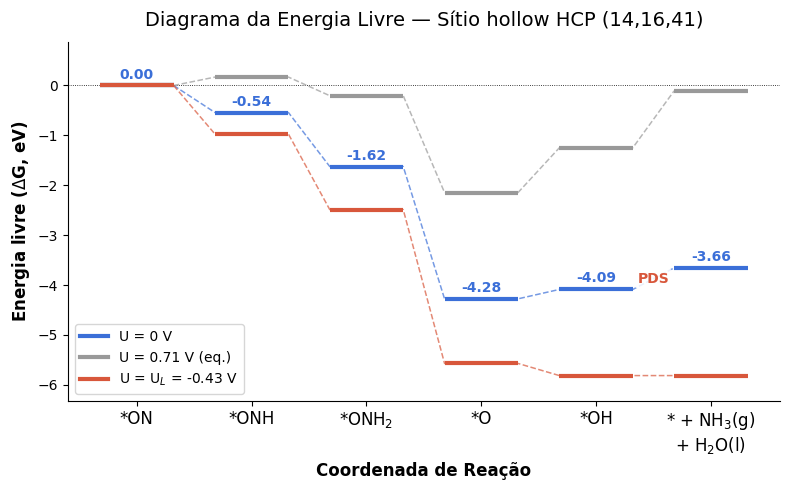


Figuras e tabela salvas em 'figuras_relatorio/':



In [28]:
# ==============================================================================
# 5. EXECUTION: GENERATE SUMMARY TABLE, PANEL GRIDS & INDIVIDUAL FIGURES
# ==============================================================================
geral = pd.read_excel(XLSX, sheet_name="Geral")

rows = []

# Generate, save, and display individual report figures for all converged sites
for pname, path in PATHS.items():
    rota_slug = "Ndown" if "N-down" in pname else "Odown"

    for conf, sname in SITES.items():
        states, g, n, UL, i, _ = analyse(path, conf)

        if np.any(~np.isfinite(g)):
            continue

        sitio_slug = SLUG_SITES.get(conf, f"site_{conf}")
        fig, ax = plt.subplots(figsize=(8, 5))
        plot_fed(
            ax,
            states,
            g,
            n,
            UL,
            i,
            f"Diagrama da Energia Livre — Sítio {sname}",
        )
        fig.tight_layout()

        fn = os.path.join(OUTPUT_DIR, f"FED_{rota_slug}_{sitio_slug}_G.png")
        fig.savefig(fn, dpi=300, bbox_inches="tight")
        plt.show()  # Display individual figure in notebook/interactive window
        plt.close(fig)

print(f"\nFiguras e tabela salvas em '{OUTPUT_DIR}/':\n")